# Covid 19 Data Analysis and Model Modelling 

In [1]:
# Initial Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
# Import for Formatting or Numbers
from matplotlib.ticker import StrMethodFormatter

In [2]:
# Setting the Seaborn Theme
sns.set_theme(style="darkgrid")

# Importing the Data

In [3]:
world = pd.read_csv("./data/worldometer_data.csv")
world

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
0,USA,North America,3.311981e+08,5032179,NaN,162804.0,NaN,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas
1,Brazil,South America,2.127107e+08,2917562,NaN,98644.0,NaN,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas
2,India,Asia,1.381345e+09,2025409,NaN,41638.0,NaN,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia
3,Russia,Europe,1.459409e+08,871894,NaN,14606.0,NaN,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe
4,South Africa,Africa,5.938157e+07,538184,NaN,9604.0,NaN,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,Montserrat,North America,4.992000e+03,13,NaN,1.0,NaN,10.0,NaN,2.0,NaN,2604.0,200.0,61.0,12220.0,NaN
205,Caribbean Netherlands,North America,2.624700e+04,13,NaN,NaN,NaN,7.0,NaN,6.0,NaN,495.0,NaN,424.0,16154.0,NaN
206,Falkland Islands,South America,3.489000e+03,13,NaN,NaN,NaN,13.0,NaN,0.0,NaN,3726.0,NaN,1816.0,520493.0,NaN
207,Vatican City,Europe,8.010000e+02,12,NaN,NaN,NaN,12.0,NaN,0.0,NaN,14981.0,NaN,NaN,NaN,Europe


# Preparing the Dataset.

### Adding Test / 1000 people in the Dataset

In [4]:
world["TestsPer1000"] = (world["TotalTests"] / world["Population"] * 1000)

### Adding the Total Cases/Death and New Cases/Death columns into one.

In [5]:
world["TotalCases"] = world["TotalCases"] + world["NewCases"].fillna(0)

world

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region,TestsPer1000
0,USA,North America,3.311981e+08,5032179.0,NaN,162804.0,NaN,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas,190.639980
1,Brazil,South America,2.127107e+08,2917562.0,NaN,98644.0,NaN,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas,62.085210
2,India,Asia,1.381345e+09,2025409.0,NaN,41638.0,NaN,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia,16.034626
3,Russia,Europe,1.459409e+08,871894.0,NaN,14606.0,NaN,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe,203.622851
4,South Africa,Africa,5.938157e+07,538184.0,NaN,9604.0,NaN,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa,53.043515
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,Montserrat,North America,4.992000e+03,13.0,NaN,1.0,NaN,10.0,NaN,2.0,NaN,2604.0,200.0,61.0,12220.0,NaN,12.219551
205,Caribbean Netherlands,North America,2.624700e+04,13.0,NaN,NaN,NaN,7.0,NaN,6.0,NaN,495.0,NaN,424.0,16154.0,NaN,16.154227
206,Falkland Islands,South America,3.489000e+03,13.0,NaN,NaN,NaN,13.0,NaN,0.0,NaN,3726.0,NaN,1816.0,520493.0,NaN,520.492978
207,Vatican City,Europe,8.010000e+02,12.0,NaN,NaN,NaN,12.0,NaN,0.0,NaN,14981.0,NaN,NaN,NaN,Europe,NaN


In [6]:
world["TotalDeaths"] = world["TotalDeaths"] + world["NewDeaths"].fillna(0)

world

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region,TestsPer1000
0,USA,North America,3.311981e+08,5032179.0,NaN,162804.0,NaN,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas,190.639980
1,Brazil,South America,2.127107e+08,2917562.0,NaN,98644.0,NaN,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas,62.085210
2,India,Asia,1.381345e+09,2025409.0,NaN,41638.0,NaN,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia,16.034626
3,Russia,Europe,1.459409e+08,871894.0,NaN,14606.0,NaN,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe,203.622851
4,South Africa,Africa,5.938157e+07,538184.0,NaN,9604.0,NaN,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa,53.043515
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,Montserrat,North America,4.992000e+03,13.0,NaN,1.0,NaN,10.0,NaN,2.0,NaN,2604.0,200.0,61.0,12220.0,NaN,12.219551
205,Caribbean Netherlands,North America,2.624700e+04,13.0,NaN,NaN,NaN,7.0,NaN,6.0,NaN,495.0,NaN,424.0,16154.0,NaN,16.154227
206,Falkland Islands,South America,3.489000e+03,13.0,NaN,NaN,NaN,13.0,NaN,0.0,NaN,3726.0,NaN,1816.0,520493.0,NaN,520.492978
207,Vatican City,Europe,8.010000e+02,12.0,NaN,NaN,NaN,12.0,NaN,0.0,NaN,14981.0,NaN,NaN,NaN,Europe,NaN


In [7]:
# Cheking if some data is empty in these added columns
print(world["TotalCases"].isna().sum())
print(world["TotalDeaths"].isna().sum())

0
21


In [8]:
# Print only those columns which are empty.
world[world["TotalDeaths"].isna()]

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region,TestsPer1000
168,Mongolia,Asia,3283344.0,293.0,NaN,NaN,NaN,260.0,NaN,33.0,1.0,89.0,NaN,38334.0,11675.0,WesternPacific,11.675292
169,Eritrea,Africa,3551175.0,282.0,NaN,NaN,NaN,225.0,NaN,57.0,NaN,79.0,NaN,NaN,NaN,Africa,NaN
172,Faeroe Islands,Europe,48882.0,266.0,NaN,NaN,NaN,192.0,NaN,74.0,1.0,5442.0,NaN,43045.0,880590.0,NaN,880.589992
174,Cambodia,Asia,16741375.0,243.0,NaN,NaN,NaN,210.0,NaN,33.0,1.0,15.0,NaN,67807.0,4050.0,WesternPacific,4.050265
177,Gibraltar,Europe,33690.0,190.0,NaN,NaN,NaN,184.0,NaN,6.0,NaN,5640.0,NaN,23063.0,684565.0,NaN,684.565153
184,Seychelles,Africa,98408.0,126.0,NaN,NaN,NaN,124.0,NaN,2.0,NaN,1280.0,NaN,NaN,NaN,Africa,NaN
186,Bhutan,Asia,772443.0,105.0,NaN,NaN,NaN,93.0,NaN,12.0,NaN,136.0,NaN,54589.0,70671.0,South-EastAsia,70.670587
190,French Polynesia,Australia/Oceania,281072.0,64.0,NaN,NaN,NaN,62.0,NaN,2.0,NaN,228.0,NaN,5849.0,20810.0,NaN,20.809615
191,St. Vincent Grenadines,North America,110976.0,56.0,NaN,NaN,NaN,46.0,NaN,10.0,NaN,505.0,NaN,2447.0,22050.0,NaN,22.049813
193,Macao,Asia,650193.0,46.0,NaN,NaN,NaN,46.0,NaN,0.0,NaN,71.0,NaN,4071.0,6261.0,NaN,6.261218


### Dropping the New Cases and New Deaths Columns.

In [9]:
# Dropping the columns which are empty
world.drop("NewCases", axis=1, inplace = True)

world.drop("NewDeaths", axis=1, inplace = True)

world

,Country/Region,Continent,Population,TotalCases,TotalDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region,TestsPer1000
0,USA,North America,3.311981e+08,5032179.0,162804.0,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas,190.639980
1,Brazil,South America,2.127107e+08,2917562.0,98644.0,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas,62.085210
2,India,Asia,1.381345e+09,2025409.0,41638.0,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia,16.034626
3,Russia,Europe,1.459409e+08,871894.0,14606.0,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe,203.622851
4,South Africa,Africa,5.938157e+07,538184.0,9604.0,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa,53.043515
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,Montserrat,North America,4.992000e+03,13.0,1.0,10.0,NaN,2.0,NaN,2604.0,200.0,61.0,12220.0,NaN,12.219551
205,Caribbean Netherlands,North America,2.624700e+04,13.0,NaN,7.0,NaN,6.0,NaN,495.0,NaN,424.0,16154.0,NaN,16.154227
206,Falkland Islands,South America,3.489000e+03,13.0,NaN,13.0,NaN,0.0,NaN,3726.0,NaN,1816.0,520493.0,NaN,520.492978
207,Vatican City,Europe,8.010000e+02,12.0,NaN,12.0,NaN,0.0,NaN,14981.0,NaN,NaN,NaN,Europe,NaN


# EDA (Exploratory Data Analysis)

### Now we will make Different Charts Related to Different factors on which Corona i.e Covid-19 had affects on different parts of the world.

## Top 10 Contries by Death

C:\Users\{Sachin}\AppData\Local\Temp\ipykernel_9000\3294891154.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x=top10_deaths["TotalDeaths"], y=top10_deaths.index, palette='viridis', ax=ax)


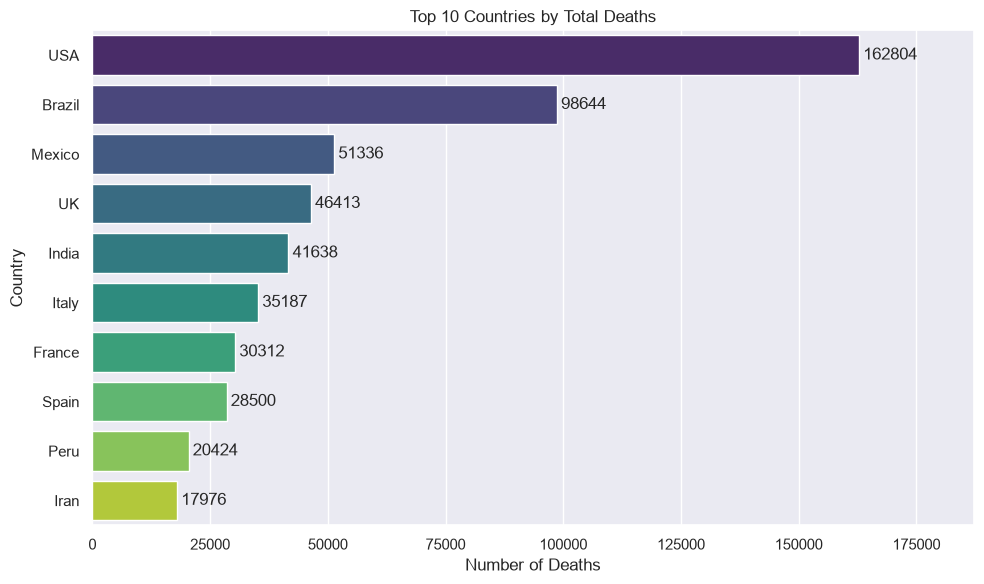

In [ ]:
# Top 10 countries with the highest deaths.
top10_deaths = world.set_index("Country/Region").sort_values("TotalDeaths", ascending=False).head(10)

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Changing the color scheme of the Bars
colors = plt.cm.viridis(np.linspace(0, 1, len(top10_deaths)))

# Create Horizontal Bars
bars = sns.barplot(
	x=top10_deaths["TotalDeaths"], 
    y=top10_deaths.index,
    palette='viridis', 
    ax=ax
)

# Add labels in the bars
for container in ax.containers:
  ax.bar_label(container, padding=3)
ax.margins(x=0.15)

# Create labels and titles
ax.set_xlabel("Number of Deaths")
ax.set_ylabel("Country")
ax.set_title("Top 10 Countries by Total Deaths")

plt.tight_layout()
plt.show()

## Top 10 Countries by Infection

C:\Users\{Sachin}\AppData\Local\Temp\ipykernel_9000\2040936238.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


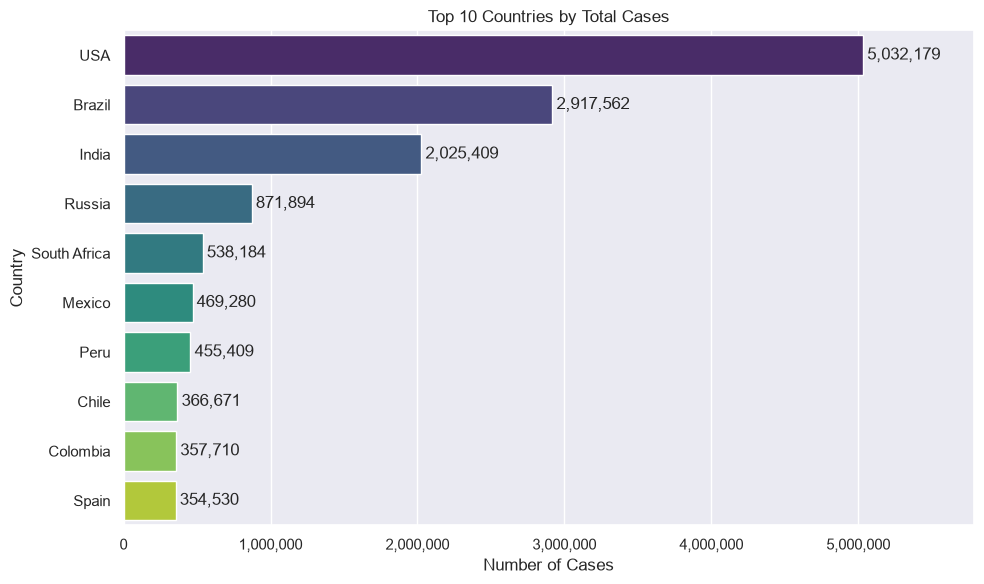

In [23]:
# Top 10 countires by Infection Rates
top10_cases = world.set_index("Country/Region").sort_values("TotalCases", ascending=False).head(10)

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Create Horizontal Bars
bars = sns.barplot(
	x=top10_cases["TotalCases"],
	y=top10_cases.index, 
  	palette='viridis', 
  	ax=ax
)

# Add labels in the bars
ax.margins(x=0.15)

# Add labels in the bars
for container in ax.containers:
  ax.bar_label(container, fmt="{:,.0f}", padding=3)
ax.margins(x=0.15)

# Create labels and titles
ax.set_xlabel("Number of Cases")
ax.set_ylabel("Country")
ax.set_title("Top 10 Countries by Total Cases")

# Remove scientific notation
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

# Top 10 Tested Countries

C:\Users\{Sachin}\AppData\Local\Temp\ipykernel_9000\1252656067.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


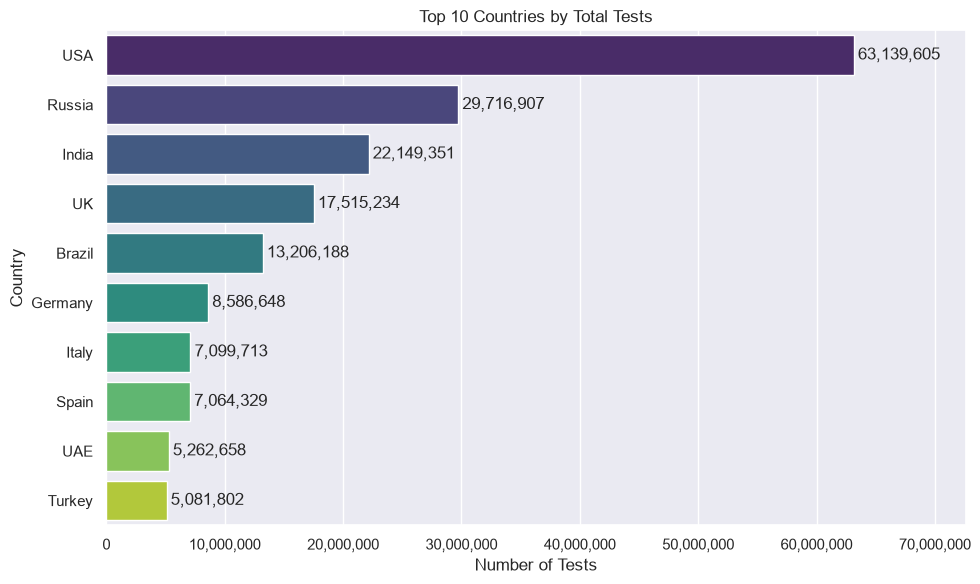

In [24]:
# Top 10 countries with the highest deaths.
top10_deaths = world.set_index("Country/Region").sort_values("TotalTests", ascending=False).head(10)

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Changing the color scheme of the Bars
colors = plt.cm.viridis(np.linspace(0, 1, len(top10_deaths)))

# Create Horizontal Bars
bars = sns.barplot(
	x=top10_deaths["TotalTests"], 
    y=top10_deaths.index,
    palette='viridis', 
    ax=ax
)

# Add labels in the bars
for container in ax.containers:
  ax.bar_label(container, fmt="{:,.0f}", padding=3)
ax.margins(x=0.15)

# Create labels and titles
ax.set_xlabel("Number of Tests")
ax.set_ylabel("Country")
ax.set_title("Top 10 Countries by Total Tests")

# Remove scientific notation
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

## Total Cases per Million


C:\Users\{Sachin}\AppData\Local\Temp\ipykernel_9000\2651483426.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=cases_per_million.index, x=cases_per_million["Tot Cases/1M pop"], palette='viridis', ax=ax)


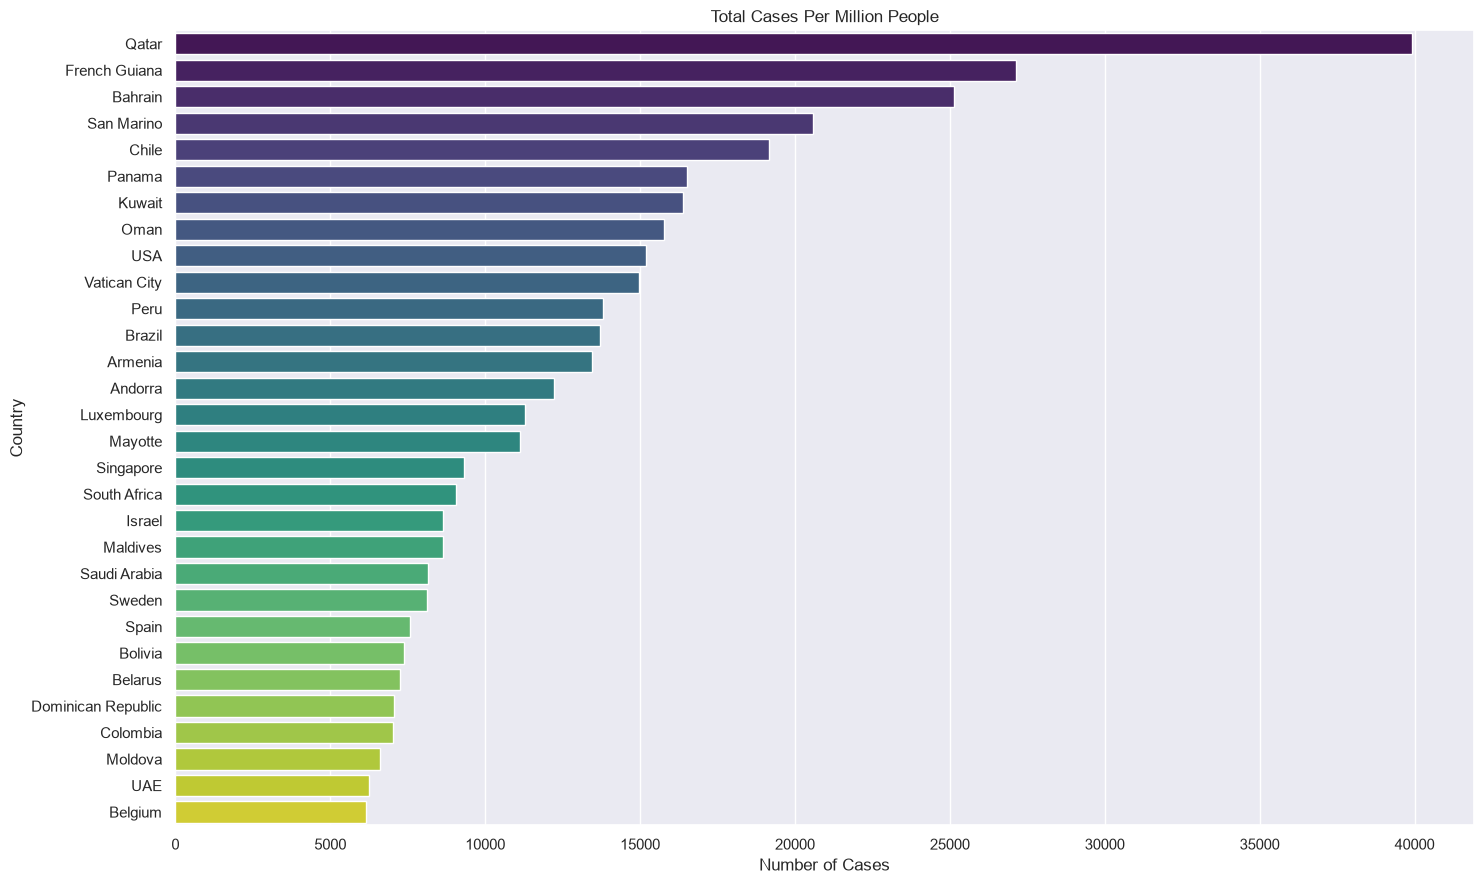

In [ ]:
# Total Cases per Million People
cases_per_million = world.set_index("Country/Region").sort_values("Tot Cases/1M pop", ascending=False).head(30)

# Create figure and axis
fig, ax = plt.subplots(figsize=(15, 9))

# Create Horizontal Bars
sns.barplot(
    y=cases_per_million.index, 
    x=cases_per_million["Tot Cases/1M pop"], 
    palette='viridis', 
    ax=ax
)

# Create labels and titles
ax.set_xlabel("Number of Cases")
ax.set_ylabel("Country")
ax.set_title("Total Cases Per Million People")
ax.autoscale(enable=True, axis='x', tight=False)

plt.tight_layout()
plt.show()

## Total Deaths per Million

C:\Users\{Sachin}\AppData\Local\Temp\ipykernel_9000\2320152175.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=deaths_per_million.index, x=deaths_per_million["Deaths/1M pop"], palette='viridis', ax=ax)


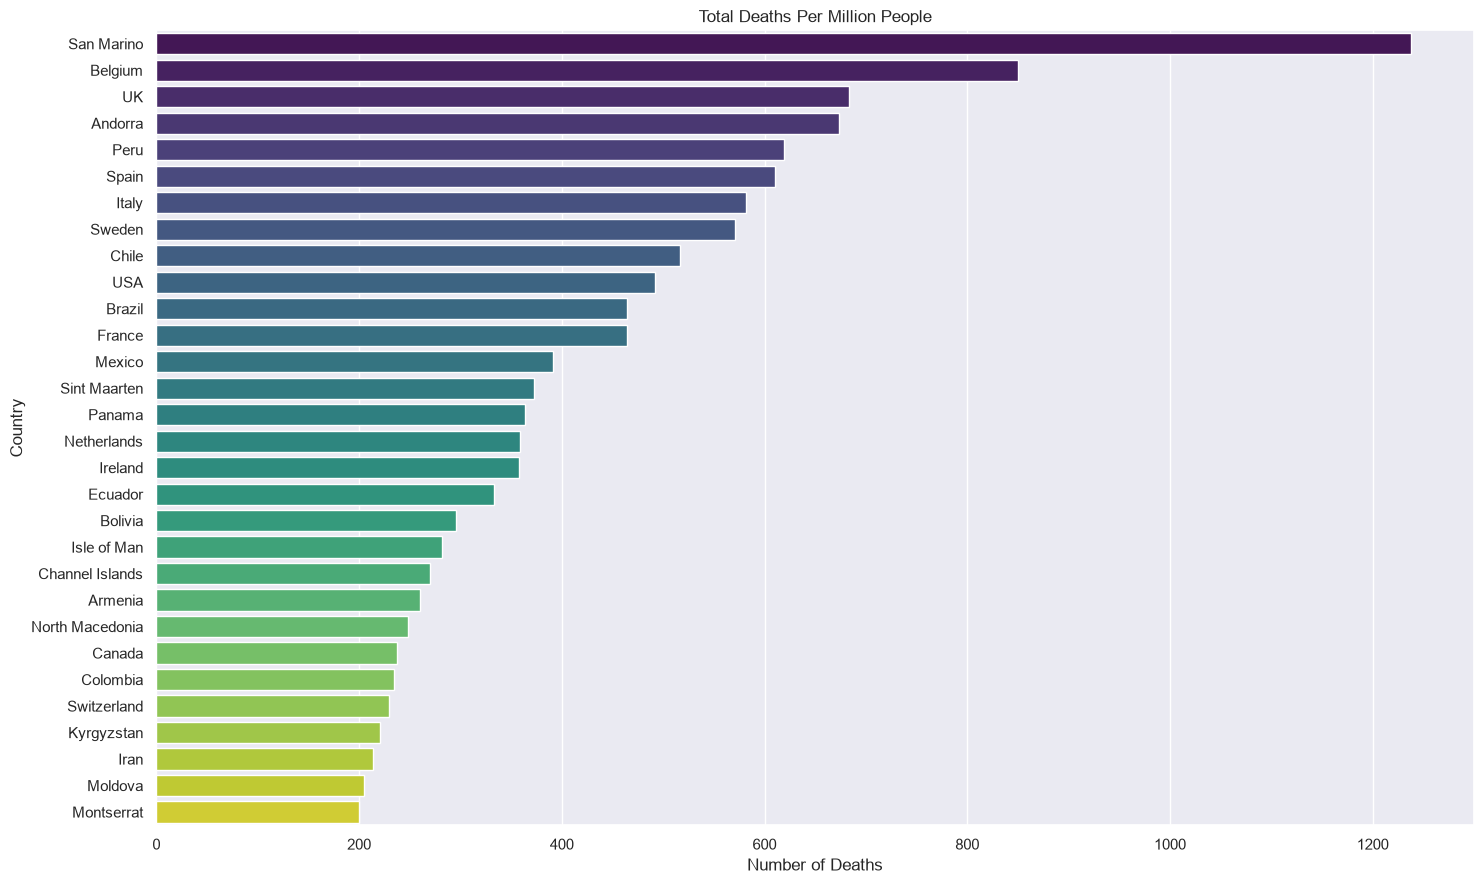

In [ ]:
# Total Deaths per Million People
deaths_per_million = world.set_index("Country/Region").sort_values("Deaths/1M pop", ascending=False).head(30)

# Create figure and axis
fig, ax = plt.subplots(figsize=(15, 9))

# Create Horizontal Bars
sns.barplot(
    y=deaths_per_million.index, 
    x=deaths_per_million["Deaths/1M pop"], 
    palette='viridis', 
    ax=ax
)

# Create labels and titles
ax.set_xlabel("Number of Deaths")
ax.set_ylabel("Country")
ax.set_title("Total Deaths Per Million People")
ax.autoscale(enable=True, axis='x', tight=False)

plt.tight_layout()
plt.show()

## Total Tests per Thousand

C:\Users\{Sachin}\AppData\Local\Temp\ipykernel_9000\131858333.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


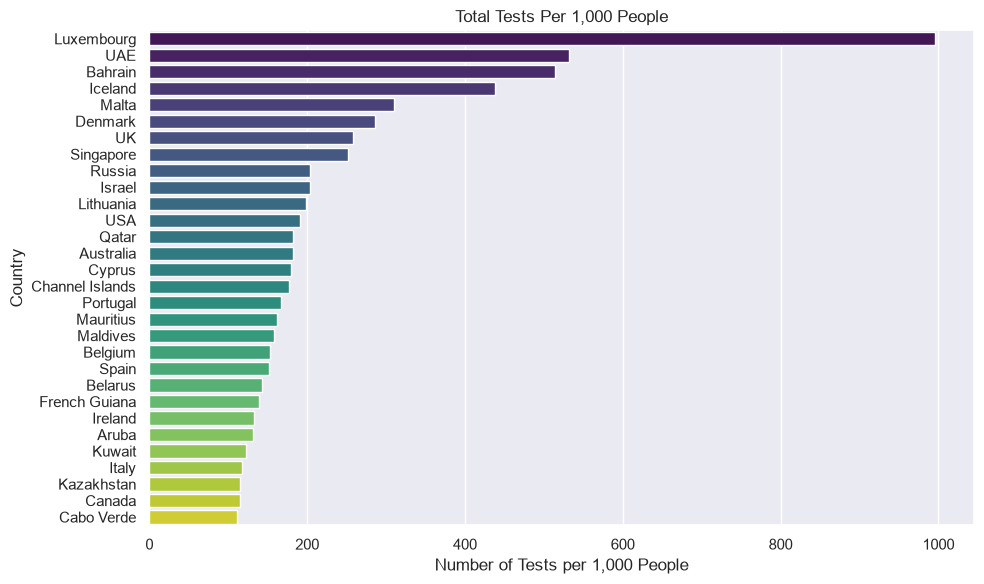

In [17]:
# Total Deaths per Thousand People

plot_data = (
    world
    .dropna(subset=["TestsPer1000"])
    .loc[world["Population"] >= 100_000]
    .sort_values("TestsPer1000", ascending=False)
    .head(30)
)

# Set country as index and sort by tests per 1,000 people
tests_per_1000 = (plot_data.set_index("Country/Region").sort_values("TestsPer1000", ascending=False).head(30))

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Create horizontal bars
sns.barplot(
    y=tests_per_1000.index,
    x=tests_per_1000["TestsPer1000"],
    palette="viridis",
    ax=ax
)

# Create labels and title
ax.set_xlabel("Number of Tests per 1,000 People")
ax.set_ylabel("Country")
ax.set_title("Total Tests Per 1,000 People")

# Adjust x-axis
ax.autoscale(enable=True, axis="x", tight=False)

plt.tight_layout()
plt.show()

## Population vs Tests Performed

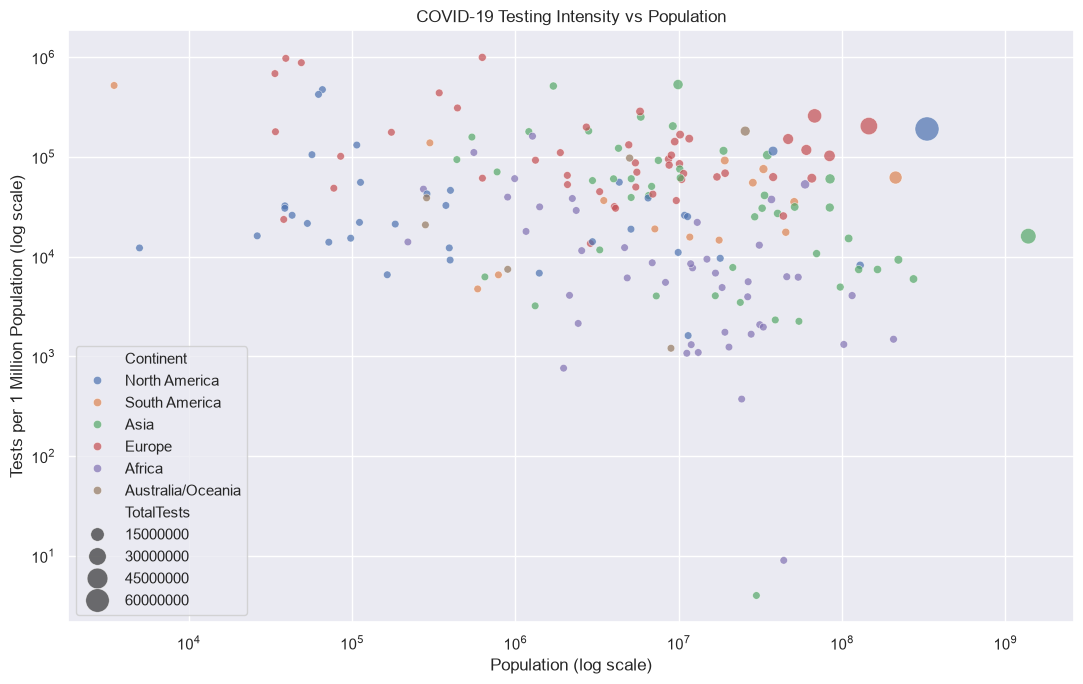

In [15]:
# Total Tests per Million People
fig, ax = plt.subplots(figsize=(11, 7))

sns.scatterplot(
    data=world,
    x="Population",
    y="Tests/1M pop",
    hue="Continent",
    size="TotalTests",
    sizes=(30, 300),
    alpha=0.7,
    ax=ax
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Population (log scale)")
ax.set_ylabel("Tests per 1 Million Population (log scale)")
ax.set_title("COVID-19 Testing Intensity vs Population")

plt.tight_layout()
plt.show()